Enrollment No: 240840116029

Practical 5: Analyze datasets using correlation, covariance, outlier detection, and distribution analysis.

Step 1: Import the pandas library

In [ ]:
#Pandas is used to create, read, modify, and analyze tabular data.
import pandas as pd
import matplotlib.pyplot as plt

Step 2: Create a sample data

In [ ]:
# Create a year data
Data = {
    "Student_Id":[101,102,103,104,105,106,107,108,109,110,111,112,113,114,115],
    "Study_Hours":[2,3,4,5,6,7,8,9,3,4,5,6,7,10,1],
    "Attendance" :[65,70,75,80,82,85,90,92,68,74,78,84,88,95,40],
    "Assignment_Score" :[55,60,65,70,72,78,82,88,62,67,71,76,80,95,35],
    "Final_Marks" :[50,55,62,68,72,78,82,90,58,63,69,75,81,98,25]
}

In [ ]:
#Convert the dictionary into a Pandas DataFrame for easier data manipulation.
df = pd.DataFrame(Data)
df

,Student_Id,Study_Hours,Attendance,Assignment_Score,Final_Marks
0,101,2,65,55,50
1,102,3,70,60,55
2,103,4,75,65,62
3,104,5,80,70,68
4,105,6,82,72,72
5,106,7,85,78,78
6,107,8,90,82,82
7,108,9,92,88,90
8,109,3,68,62,58
9,110,4,74,67,63


Step 3: Inspect the dataset

In [ ]:
# Display first five records
df.head()

,Student_Id,Study_Hours,Attendance,Assignment_Score,Final_Marks
0,101,2,65,55,50
1,102,3,70,60,55
2,103,4,75,65,62
3,104,5,80,70,68
4,105,6,82,72,72


In [ ]:
# Display information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Student_Id        15 non-null     int64
 1   Study_Hours       15 non-null     int64
 2   Attendance        15 non-null     int64
 3   Assignment_Score  15 non-null     int64
 4   Final_Marks       15 non-null     int64
dtypes: int64(5)
memory usage: 732.0 bytes


In [ ]:
# Display the number of row and columns
df.shape

(15, 5)

In [ ]:
# Generate descriptive statistics for all numerical columns
df.describe()

,Student_Id,Study_Hours,Attendance,Assignment_Score,Final_Marks
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,108.000000,5.333333,77.733333,70.400000,68.400000
std,4.472136,2.581989,13.718948,14.500246,17.759504
min,101.000000,1.000000,40.000000,35.000000,25.000000
25%,104.500000,3.500000,72.000000,63.500000,60.000000
50%,108.000000,5.000000,80.000000,71.000000,69.000000
75%,111.500000,7.000000,86.500000,79.000000,79.500000
max,115.000000,10.000000,95.000000,95.000000,98.000000


Step 4: Calculate correlation

In [ ]:
#Calculate the correlation between study hours and final marks
correlation = df["Study_Hours"].corr(df["Final_Marks"])
print("Correlation:", correlation)


Correlation: 0.9626650934516625


Step 5: Calculate correlation matrix

In [ ]:
#Calculate correlation among numerical variables.
correlation_matrix = df.corr()
print(correlation_matrix)

                    Student_Id  Study_Hours    Attendance  Assignment_Score  \
Student_Id        1.000000e+00     0.247436 -7.279626e-16          0.136585   
Study_Hours       2.474358e-01     1.000000  9.201931e-01          0.961552   
Attendance       -7.279626e-16     0.920193  1.000000e+00          0.981905   
Assignment_Score  1.365851e-01     0.961552  9.819053e-01          1.000000   
Final_Marks       1.286063e-01     0.962665  9.837631e-01          0.999268   

                  Final_Marks  
Student_Id           0.128606  
Study_Hours          0.962665  
Attendance           0.983763  
Assignment_Score     0.999268  
Final_Marks          1.000000  


Step 6: Visualize correlation using scatter plot

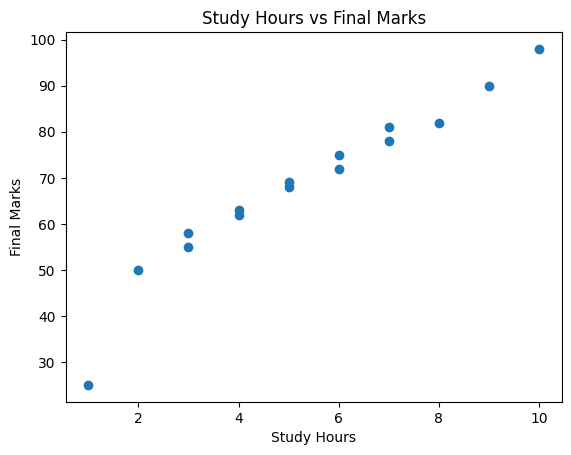

In [ ]:
#Create a scatter plot to visualize the relationship between study hours and final marks.
plt.scatter(df["Study_Hours"], df["Final_Marks"])
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.title("Study Hours vs Final Marks")
plt.show()

Step 7: Calculate Covariance Matrix

In [ ]:
#Calculate covariance between study hours and Final marks.
covariance_matrix = df.cov()
print(covariance_matrix)

                    Student_Id  Study_Hours    Attendance  Assignment_Score  \
Student_Id        2.000000e+01     2.857143 -1.015061e-15          8.857143   
Study_Hours       2.857143e+00     6.666667  3.259524e+01         36.000000   
Attendance       -1.015061e-15    32.595238  1.882095e+02        195.328571   
Assignment_Score  8.857143e+00    36.000000  1.953286e+02        210.257143   
Final_Marks       1.021429e+01    44.142857  2.396857e+02        257.328571   

                  Final_Marks  
Student_Id          10.214286  
Study_Hours         44.142857  
Attendance         239.685714  
Assignment_Score   257.328571  
Final_Marks        315.400000  


Step 8: Calculate Covariance Matrix

In [ ]:
#Select the numerical columns for covariance analysis.
covariance_matrix

,Student_Id,Study_Hours,Attendance,Assignment_Score,Final_Marks
Student_Id,2.000000e+01,2.857143,-1.015061e-15,8.857143,10.214286
Study_Hours,2.857143e+00,6.666667,3.259524e+01,36.000000,44.142857
Attendance,-1.015061e-15,32.595238,1.882095e+02,195.328571,239.685714
Assignment_Score,8.857143e+00,36.000000,1.953286e+02,210.257143,257.328571
Final_Marks,1.021429e+01,44.142857,2.396857e+02,257.328571,315.400000


Step 9: detect outliers using IQR (Select the Final_Marks columns for outlier analysis.)

In [ ]:
Q1 = df["Final_Marks"].quantile(0.25)
Q3 = df["Final_Marks"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)


Q1: 60.0
Q3: 79.5
IQR: 19.5
Lower Bound: 30.75
Upper Bound: 108.75


Step 10: Identify Outliers

In [ ]:
#Select records where Final_Marks are below the lower bound or above the upper bound.
outliers = df[
    (df["Final_Marks"] < lower_bound) |
    (df["Final_Marks"] > upper_bound)
    ]
print("Outliers:")
print(outliers)

Outliers:
    Student_Id  Study_Hours  Attendance  Assignment_Score  Final_Marks
14         115            1          40                35           25


Step 11: Count Outliers(Count the total number of detected outliers.)

In [ ]:
# Count total number of outliers
outlier_count = len(outliers)

print("Total number of outliers:", outlier_count)


Total number of outliers: 1


Step 12: Visualize outliers using box plot.

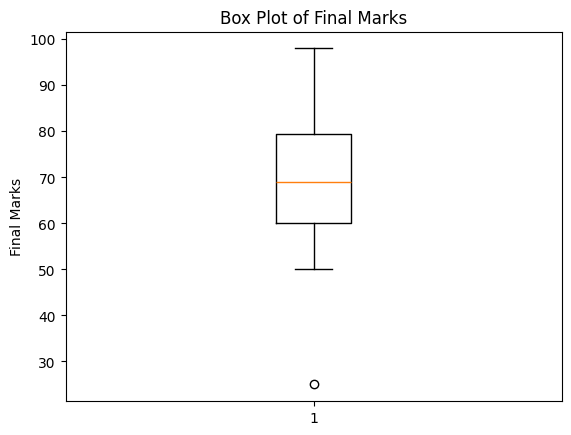

In [ ]:
# Box plot for Final_Marks
plt.boxplot(df["Final_Marks"])

plt.title("Box Plot of Final Marks")
plt.ylabel("Final Marks")
plt.show()


Step 13: Create a Histogram (Create a histogram to observe the distribution of final marks.)

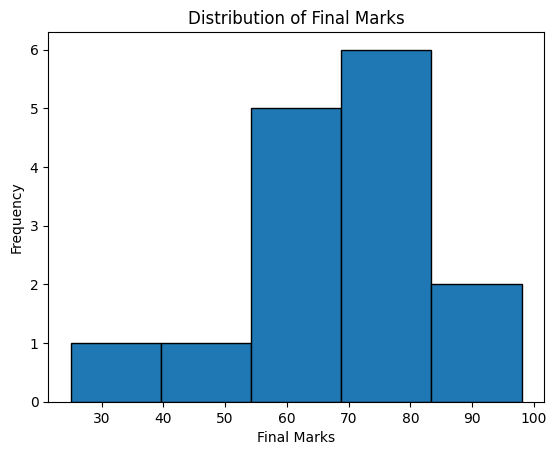

In [ ]:
# Create histogram for Final_Marks
plt.hist(df["Final_Marks"], bins=5, edgecolor="black")

plt.title("Distribution of Final Marks")
plt.xlabel("Final Marks")
plt.ylabel("Frequency")
plt.show()


Step 14: Analyze distribution using skewness

In [ ]:
#Calculate the skeweness of final marks.
skewness = df["Final_Marks"].skew()
print("Skewness:", skewness)

Skewness: -0.7383380071904277


Step 15: Calculate kurtosis

In [ ]:
# Calculate the kurtosis of final marks.
kurtosis = df["Final_Marks"].kurtosis()
print("Kurtosis:", kurtosis)

Kurtosis: 1.4936683306648835


Step 16: Distribution of study hours(Create a histogram for study hours.)

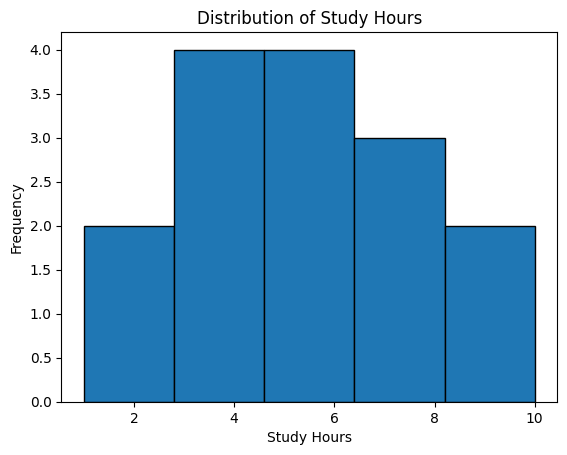

In [ ]:
# Create histogram for Study_Hours
plt.hist(df["Study_Hours"], bins=5, edgecolor="black")

plt.title("Distribution of Study Hours")
plt.xlabel("Study Hours")
plt.ylabel("Frequency")
plt.show()


Step 17: Compare variable using box plots (Create box plots for multiple numerical variables.)

/tmp/ipykernel_1074/2105769641.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


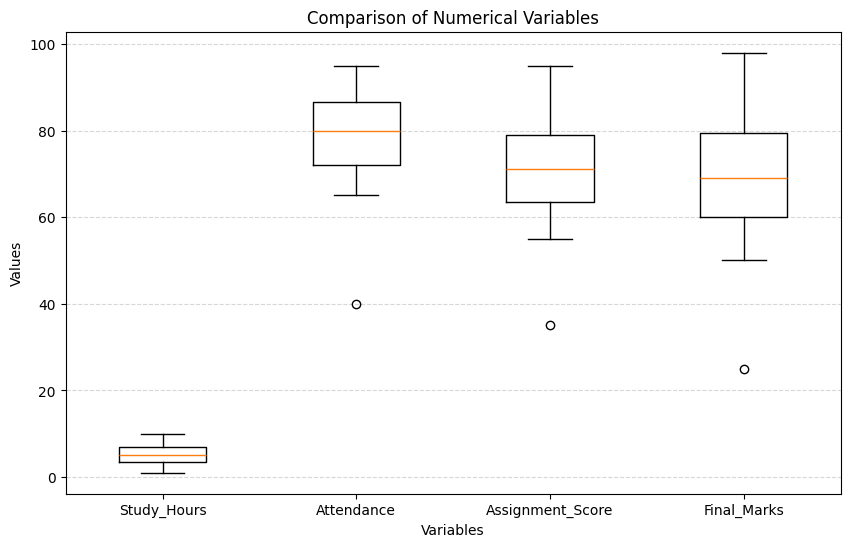

In [ ]:
# Select numerical variables
numerical_data = df[
    ["Study_Hours", "Attendance", "Assignment_Score", "Final_Marks"]
]

# Create box plots
plt.figure(figsize=(10, 6))
plt.boxplot(
    numerical_data.values,
    labels=numerical_data.columns
)

plt.title("Comparison of Numerical Variables")
plt.xlabel("Variables")
plt.ylabel("Values")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()


Step 18: Generate a statistical summary

In [ ]:
# Generate statistical summary
statistical_summary = df[
    ["Study_Hours", "Attendance", "Assignment_Score", "Final_Marks"]
].describe()

print(statistical_summary)


       Study_Hours  Attendance  Assignment_Score  Final_Marks
count    15.000000   15.000000         15.000000    15.000000
mean      5.333333   77.733333         70.400000    68.400000
std       2.581989   13.718948         14.500246    17.759504
min       1.000000   40.000000         35.000000    25.000000
25%       3.500000   72.000000         63.500000    60.000000
50%       5.000000   80.000000         71.000000    69.000000
75%       7.000000   86.500000         79.000000    79.500000
max      10.000000   95.000000         95.000000    98.000000


Step 19: Save the analysis dataset

In [ ]:
# Save the analysis dataset
df.to_csv("student_analysis_dataset.csv", index=False)
print("Analysis dataset saved successfully!")

Analysis dataset saved successfully!


Step 20: Download the csv in google colab

In [ ]:
from google.colab import files

# Download the CSV file
files.download("student_analysis_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>